# Hälsostudie
Av: Lovis Wikström

## Del 1 - Grundläggande analys och statistik

### 1. Introduktion
I denna rapporten kommer vi att undersöka data från en hälsostudie samt redovisa en analys utifrån denna. 



### 2. Importering och inläsning
Här läses den datan vi utgår ifrån att läsas in, samt importerar de paket vi kommer att använda oss av i resten av rapporten.

In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
np.random.seed(42)

df=pd.read_csv("../data/health_study_dataset.csv")

### 3. Översikt
Vi börjar med att undersöka datan vi har, här går vi igenom och tittar på och kontrollerar det vi jobbar med och ser till att allt är som det ska, att det inte finns dubletter och så vidare.
Vi börjar med att titta på hur många rader och kolumner vi har, samt de fem översta raderna för att få en idé om vad det är för data vi har att arbeta med.

In [34]:
print("Antal rader och kolumner:", df.shape)
df.head()


Antal rader och kolumner: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


Här kontrolleras saknade värden och dubletter, samt kikar på deskriptiv statistik. 
Vi kan konstatera att det inte saknas några värden och att alla rader är unika, alltså förekommer inga dubletter.

För enkelhetens skull avrundar vi till två decimaler för att få en bättre överblick.

In [35]:
display(df.describe().round(2))

print("Saknade värden:")
print(df.isna().sum())
print("Dubletter:", df.duplicated().sum())



,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,400.50,49.43,171.85,73.41,149.18,4.93,0.06
std,231.08,14.50,9.80,13.69,12.79,0.85,0.24
min,1.00,18.00,144.40,33.70,106.80,2.50,0.00
25%,200.75,39.00,164.78,64.80,140.90,4.33,0.00
50%,400.50,50.00,171.35,73.20,149.40,4.97,0.00
75%,600.25,59.00,178.92,82.60,157.60,5.48,0.00
max,800.00,90.00,200.40,114.40,185.90,7.88,1.00


Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
Dubletter: 0


Här gör vi en sammanställning av median, medelvärde, minsta och största värde i kategorierna ålder, vikt, systoliskt blodtryck samt förekomst av sjukdom av de kolumnerna vi kommer att titta mest på, vi har redan värdena ovan, men detta ger oss en lite tydligare bild av just dessa. 

Även här avrundat till två decimaler.

In [36]:
columns = [
    "age", "weight", "systolic_bp", "disease"]

df[columns].agg(["mean", "median", "min", "max"]).round(2)

,age,weight,systolic_bp,disease
mean,49.43,73.41,149.18,0.06
median,50.00,73.20,149.40,0.00
min,18.00,33.70,106.80,0.00
max,90.00,114.40,185.90,1.00


### 4. Visualisering
Här undersöker vi deltagarnas hälsodata med hjälp av visualiseringar i fyra olika diagram.
1. Histogram: Fördelningen av systoliskt blodtryck. 

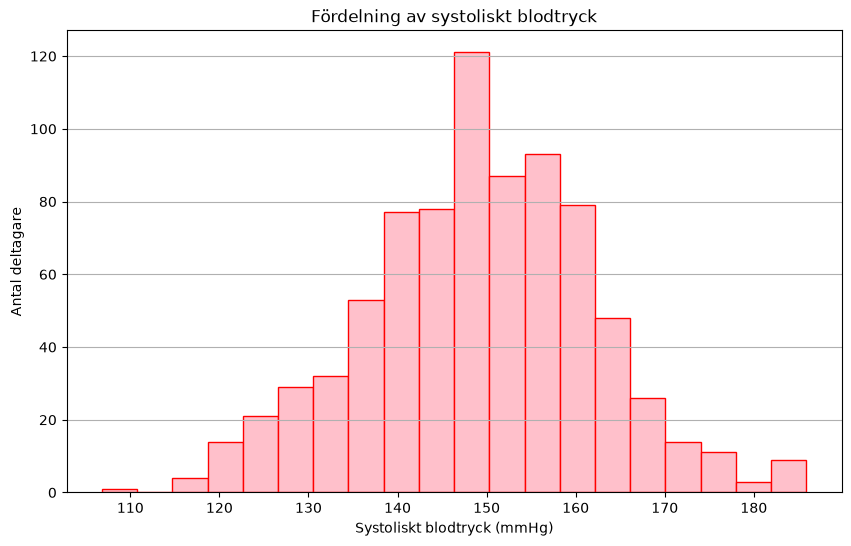

In [37]:
plt.figure(figsize=(10, 6))
plt.hist(df["systolic_bp"], bins=20, color="pink", edgecolor="red")

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y")
plt.show()

2. Låddiagram: Viktfördelningen per kön.

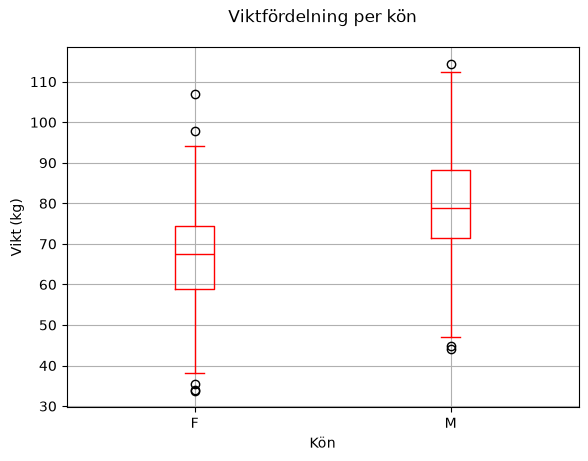

In [38]:
fig, ax = plt.subplots()
df.boxplot(column="weight", by="sex", ax=ax, color="red")

fig.suptitle("Viktfördelning per kön")

ax.set_title("")
ax.set_xlabel("Kön")
ax.set_ylabel("Vikt (kg)")

plt.show()

3. Stapeldiagram: Fördelningen mellan rökare/icke-rökare.

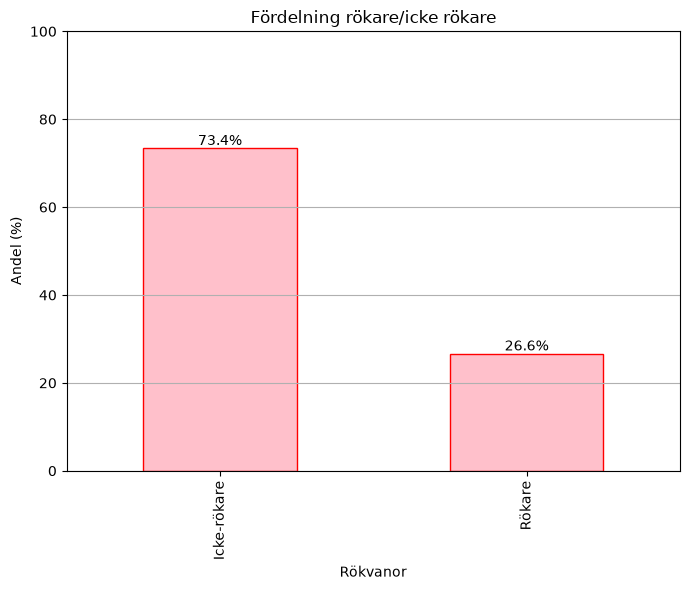

In [39]:
smoker_percent = df["smoker"].value_counts(normalize=True) * 100
smoker_percent = smoker_percent.rename({
    "No": "Icke-rökare",
    "Yes": "Rökare"
})
smoker_percent.plot(
    kind="bar",
    color="pink",
    edgecolor="red",
    figsize=(7,6)
    )
plt.grid(axis="y")
plt.title("Fördelning rökare/icke rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

4. Spridningsdiagram: Sambandet mellan ålder och systoliskt blodtryck.

    Visas här med den linjära regressionen. 

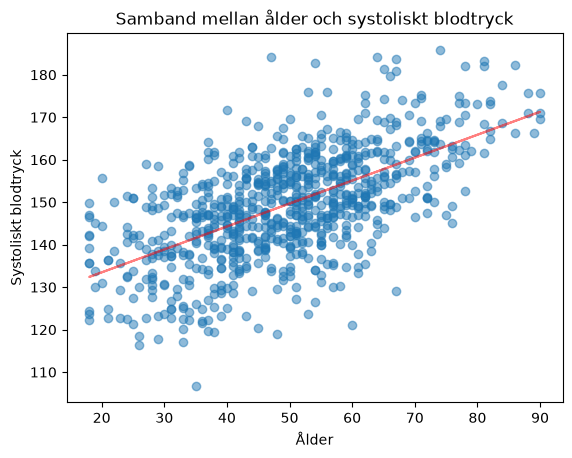

Det förväntade systoliska blodtrycket ökar med cirka 0.54 mmHg / år.


In [40]:
plt.scatter(df["age"], df["systolic_bp"], alpha=0.5)
plt.title("Samband mellan ålder och systoliskt blodtryck")
plt.xlabel("Ålder")
plt.ylabel("Systoliskt blodtryck")

x = df["age"]
y = df["systolic_bp"]
k, m = np.polyfit(x, y, 1).round(2)

plt.plot(x, k*x + m, color="red", alpha=0.5)
plt.show()
print("Det förväntade systoliska blodtrycket ökar med cirka", k, "mmHg / år.")

### 5. Sjukdomsförekomst
I denna delen kikar vi närmre på sjukdomsförekomsten. 
Vi tar reda på hur ofta det förekommer och undersöker om det finns någon effekt av slumpmässig variation.

In [41]:
disease_rate = df["disease"].mean()
print(f"Dokumenterad andel med sjukdom: {disease_rate:.2%} av {len(df)} deltagare.")
print(f"Antal deltagare med sjukdomen i undersökningen är {df["disease"].sum()}.")



Dokumenterad andel med sjukdom: 5.88% av 800 deltagare.
Antal deltagare med sjukdomen i undersökningen är 47.


Vi undersöker slumpmässig variation genom att göra en simulering.

In [42]:
rng = np.random.default_rng(42)

sim_disease = rng.binomial(
    n=1,
    p= disease_rate,
    size=1000
)
dif_disease = (disease_rate - sim_disease.mean()) * 100
print(f"Dokumenterad andel med sjukdom: {disease_rate:.2%}")
print(f"Simulerade andelen med sjukdom: {sim_disease.mean():.2%}")
print(f"Skillnaden mellan dokumenterade och simulerade fall: {dif_disease:.2f} procentenheter.")


Dokumenterad andel med sjukdom: 5.88%
Simulerade andelen med sjukdom: 5.40%
Skillnaden mellan dokumenterade och simulerade fall: 0.47 procentenheter.


Jämför man den dokumenterade andelen och den simulerade andelen så är skillnaden liten, och visar på att vi har fått ett resultat nära den verkliga sjukdomsförekomsten. 

Skillnad kan förekomma på grund av slumpmässig variation. 


### 6. Konfidensintervall: systoliskt blodtryck
Här räknar vi ett konfidensintervall på 95% för systoliskt blodtryck. 
Vi använder oss av normalapproximation. 


In [43]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
n = bp.count()

se = std_bp / np.sqrt(n)

print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"Standardavvikelse: {std_bp:.2f} mmHg")
print(f"Antal personer: {n}")
print(f"Standardfel: {se:.2f} mmHg")

Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Antal personer: 800
Standardfel: 0.45 mmHg


### 7. Hypotesprövning
Dessa hypoteser testas:
Nollhypotes (H0): Det finns ingen skillnad i systoliskt blodtryck mellan rökare/icke-rökare.
Alternativhypotes (H1): Rökare har generellt högre genomsnittligt systoliskt blodtryck än icke-rökare.

Vi kommer att använda oss av ensidigt Welch t-test och signifikansnivå 5%.


In [44]:
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]
dif_bp = dif_bp = smokers.mean() - non_smokers.mean()

print(f"Antal rökare: {len(smokers)}")
print(f"Medelblodtryck för rökare: {smokers.mean().round(2)} mmHg")
print(f"Antal icke-rökare: {len(non_smokers)}")
print(f"Medelblodtryck för icke-rökare: {non_smokers.mean().round(2)} mmHg")
print(f"Skillnad i blodtryck mellan rökare/icke-rökare: {dif_bp:.2f} mmHg")

Antal rökare: 213
Medelblodtryck för rökare: 149.52 mmHg
Antal icke-rökare: 587
Medelblodtryck för icke-rökare: 149.05 mmHg
Skillnad i blodtryck mellan rökare/icke-rökare: 0.47 mmHg


In [45]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std", "median"]
).round(2)

,count,mean,std,median
smoker,,,,
No,587,149.05,12.63,149.3
Yes,213,149.52,13.27,149.5


In [46]:
smoker_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smoker_bp = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()
alpha = 0.05

t_stat, p_value = ttest_ind(smoker_bp, non_smoker_bp, equal_var=False)
difference_bp = non_smoker_bp.mean() - smoker_bp.mean()

print(f"t-värde: {t_stat:.4f}")
print(f"p-värde: {p_value:.4f}")
print("Observerad skillnad icke-rökare - rökare:", difference_bp.round(4))


if p_value < alpha:
    print("Resultat: H0 förkastas på 5%-nivån.")
    print("Det finns statistisk signifikans som stöd för att rökare har högre medel i systoliskt blodtryck.")
else:
    print("Resultat: H1 förkastas inte på 5%-nivån. ")
    print("Det finns inte statistisk signifikans som stöd för att rökare har ett högre medel i systoliskt blodtryck.")


t-värde: 0.4503
p-värde: 0.6527
Observerad skillnad icke-rökare - rökare: -0.4719
Resultat: H1 förkastas inte på 5%-nivån. 
Det finns inte statistisk signifikans som stöd för att rökare har ett högre medel i systoliskt blodtryck.
